In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files

folder = Path("q3_asthma")
folder.mkdir(exist_ok=True)

In [ ]:
import io
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

recent_raw = pd.read_csv(
    io.BytesIO(uploaded[filename])
)

# Preserve the new source file.
(folder / "asthma_recent_original.csv").write_bytes(
    uploaded[filename]
)

print("Shape:", recent_raw.shape)
print("\nColumns:")
print(recent_raw.columns.tolist())

print("\nAvailable time periods:")
print(recent_raw["TimePeriod"].value_counts().sort_index())

print("\nGeographic levels:")
print(recent_raw["GeoTypeDesc"].value_counts())

display(recent_raw.head())

Saving NYC EH Data Portal - Asthma emergency department visits (age 5 to 17) (filtered).csv to NYC EH Data Portal - Asthma emergency department visits (age 5 to 17) (filtered).csv
Shape: (59, 11)

Columns:
['TimePeriod', 'GeoTypePretty', 'GeoTypeDesc', 'GeoID', 'GeoRank', 'BoroID', 'Borough', 'Geography', 'Area', 'Number', 'Estimated annual rate per 10,000']

Available time periods:
TimePeriod
2023    59
Name: count, dtype: int64

Geographic levels:
GeoTypeDesc
Community District    59
Name: count, dtype: int64


,TimePeriod,GeoTypePretty,GeoTypeDesc,GeoID,GeoRank,BoroID,Borough,Geography,Area,Number,"Estimated annual rate per 10,000"
0,2023,CD,Community District,201,6,1,Bronx,Mott Haven and Melrose (CD1),Mott Haven and Melrose (CD1) Bronx,585,326.9
1,2023,CD,Community District,202,6,1,Bronx,Hunts Point and Longwood (CD2),Hunts Point and Longwood (CD2) Bronx,243,244.7
2,2023,CD,Community District,203,6,1,Bronx,Morrisania and Crotona (CD3),Morrisania and Crotona (CD3) Bronx,473,272.2
3,2023,CD,Community District,204,6,1,Bronx,Highbridge and Concourse (CD4),Highbridge and Concourse (CD4) Bronx,697,262.3
4,2023,CD,Community District,205,6,1,Bronx,Fordham and University Heights (CD5),Fordham and University Heights (CD5) Bronx,535,223.5


In [ ]:
# Keep only the 2023 observations.
data_2023 = recent_raw[
    recent_raw["TimePeriod"].astype(str).str.strip() == "2023"
].copy()

print("2023 observations:", len(data_2023))

if data_2023.empty:
    print("2023 is missing. Check which indicator was exported.")
else:
    print("\n2023 geographic coverage:")
    print(data_2023["GeoTypeDesc"].value_counts())

    print("\nSample observations:")
    display(data_2023.head(10))

2023 observations: 59

2023 geographic coverage:
GeoTypeDesc
Community District    59
Name: count, dtype: int64

Sample observations:


,TimePeriod,GeoTypePretty,GeoTypeDesc,GeoID,GeoRank,BoroID,Borough,Geography,Area,Number,"Estimated annual rate per 10,000"
0,2023,CD,Community District,201,6,1,Bronx,Mott Haven and Melrose (CD1),Mott Haven and Melrose (CD1) Bronx,585,326.9
1,2023,CD,Community District,202,6,1,Bronx,Hunts Point and Longwood (CD2),Hunts Point and Longwood (CD2) Bronx,243,244.7
2,2023,CD,Community District,203,6,1,Bronx,Morrisania and Crotona (CD3),Morrisania and Crotona (CD3) Bronx,473,272.2
3,2023,CD,Community District,204,6,1,Bronx,Highbridge and Concourse (CD4),Highbridge and Concourse (CD4) Bronx,697,262.3
4,2023,CD,Community District,205,6,1,Bronx,Fordham and University Heights (CD5),Fordham and University Heights (CD5) Bronx,535,223.5
5,2023,CD,Community District,206,6,1,Bronx,Belmont and East Tremont (CD6),Belmont and East Tremont (CD6) Bronx,459,281.9
6,2023,CD,Community District,207,6,1,Bronx,Kingsbridge Heights and Bedford (CD7),Kingsbridge Heights and Bedford (CD7) Bronx,619,257.7
7,2023,CD,Community District,208,6,1,Bronx,Riverdale and Fieldston (CD8),Riverdale and Fieldston (CD8) Bronx,202,151.8
8,2023,CD,Community District,209,6,1,Bronx,Parkchester and Soundview (CD9),Parkchester and Soundview (CD9) Bronx,644,215.8
9,2023,CD,Community District,210,6,1,Bronx,Throgs Neck and Co-op City (CD10),Throgs Neck and Co-op City (CD10) Bronx,261,157.1


In [ ]:
asthma = recent_raw.copy()

asthma = asthma.rename(columns={
    "TimePeriod": "year",
    "GeoID": "district_id",
    "Borough": "borough",
    "Geography": "district",
    "Number": "visits",
    "Estimated annual rate per 10,000": "rate"
})

asthma["year"] = pd.to_numeric(
    asthma["year"], errors="raise"
)

for col in ["visits", "rate"]:
    asthma[col] = pd.to_numeric(
        asthma[col].astype(str).str.replace(",", "", regex=False),
        errors="raise"
    )

# Validate the observations.
assert len(asthma) == 59
assert (asthma["year"] == 2023).all()
assert (asthma["GeoTypeDesc"] == "Community District").all()
assert asthma["district_id"].is_unique
assert asthma[["rate", "visits"]].notna().all().all()
assert np.isfinite(asthma[["rate", "visits"]]).all().all()
assert (asthma[["rate", "visits"]] >= 0).all().all()
assert asthma["borough"].nunique() == 5

asthma = asthma.sort_values(
    ["borough", "district"]
).reset_index(drop=True)

asthma.to_csv(
    folder / "asthma_2023_cleaned.csv",
    index=False
)

print("Validation passed!")
print("Community districts:", len(asthma))
print("Boroughs:", asthma["borough"].nunique())

display(asthma.head())

Validation passed!
Community districts: 59
Boroughs: 5


,year,GeoTypePretty,GeoTypeDesc,district_id,GeoRank,BoroID,borough,district,Area,visits,rate
0,2023,CD,Community District,206,6,1,Bronx,Belmont and East Tremont (CD6),Belmont and East Tremont (CD6) Bronx,459,281.9
1,2023,CD,Community District,205,6,1,Bronx,Fordham and University Heights (CD5),Fordham and University Heights (CD5) Bronx,535,223.5
2,2023,CD,Community District,204,6,1,Bronx,Highbridge and Concourse (CD4),Highbridge and Concourse (CD4) Bronx,697,262.3
3,2023,CD,Community District,202,6,1,Bronx,Hunts Point and Longwood (CD2),Hunts Point and Longwood (CD2) Bronx,243,244.7
4,2023,CD,Community District,207,6,1,Bronx,Kingsbridge Heights and Bedford (CD7),Kingsbridge Heights and Bedford (CD7) Bronx,619,257.7


In [ ]:
CITYWIDE_RATE = 143.7

asthma["above_citywide"] = (
    asthma["rate"] > CITYWIDE_RATE
)

asthma["rate_ratio"] = (
    asthma["rate"] / CITYWIDE_RATE
)

print("=== CITYWIDE COMPARISON ===")

print("NYC published rate:", CITYWIDE_RATE)
print(
    "Districts above NYC rate:",
    asthma["above_citywide"].sum()
)

print(
    "Districts at least twice NYC rate:",
    (asthma["rate_ratio"] >= 2).sum()
)

print("\n=== 10 HIGHEST-RATE DISTRICTS ===")

top10 = asthma.nlargest(10, "rate")

display(
    top10[[
        "district",
        "borough",
        "rate",
        "visits",
        "rate_ratio"
    ]].round(2)
)

print("\n=== 10 LOWEST-RATE DISTRICTS ===")

display(
    asthma.nsmallest(10, "rate")[[
        "district",
        "borough",
        "rate",
        "visits"
    ]]
)

print("\n=== HIGHEST VS LOWEST ===")

highest = asthma.loc[asthma["rate"].idxmax()]
lowest = asthma.loc[asthma["rate"].idxmin()]

print(
    f"Highest: {highest['district']} "
    f"({highest['rate']:.1f})"
)

print(
    f"Lowest: {lowest['district']} "
    f"({lowest['rate']:.1f})"
)

if lowest["rate"] > 0:
    print(
        f"Highest/lowest rate ratio: "
        f"{highest['rate'] / lowest['rate']:.2f}x"
    )

=== CITYWIDE COMPARISON ===
NYC published rate: 143.7
Districts above NYC rate: 26
Districts at least twice NYC rate: 5

=== 10 HIGHEST-RATE DISTRICTS ===


,district,borough,rate,visits,rate_ratio
16,Brownsville (CD16),Brooklyn,441.8,627,3.07
30,Central Harlem (CD10),Manhattan,396.7,619,2.76
32,East Harlem (CD11),Manhattan,375.5,628,2.61
7,Mott Haven and Melrose (CD1),Bronx,326.9,585,2.27
20,East Flatbush (CD17),Brooklyn,300.4,563,2.09
0,Belmont and East Tremont (CD6),Bronx,281.9,459,1.96
6,Morrisania and Crotona (CD3),Bronx,272.2,473,1.89
2,Highbridge and Concourse (CD4),Bronx,262.3,697,1.83
4,Kingsbridge Heights and Bedford (CD7),Bronx,257.7,619,1.79
21,East New York and Starrett City (CD5),Brooklyn,252.3,763,1.76



=== 10 LOWEST-RATE DISTRICTS ===


,district,borough,rate,visits
58,Tottenville and Great Kills (CD3),Staten Island,20.6,51
15,Borough Park (CD12),Brooklyn,20.7,99
39,Upper East Side (CD8),Manhattan,22.2,48
56,South Beach and Willowbrook (CD2),Staten Island,33.6,71
34,Greenwich Village and Soho (CD2),Manhattan,34.5,19
12,Bay Ridge and Dyker Heights (CD10),Brooklyn,34.7,70
14,Bensonhurst (CD11),Brooklyn,36.6,109
51,Rego Park and Forest Hills (CD6),Queens,37.2,43
42,Bayside and Little Neck (CD11),Queens,37.6,62
27,Sheepshead Bay (CD15),Brooklyn,39.2,106



=== HIGHEST VS LOWEST ===
Highest: Brownsville (CD16) (441.8)
Lowest: Tottenville and Great Kills (CD3) (20.6)
Highest/lowest rate ratio: 21.45x


In [ ]:
borough_summary = asthma.groupby("borough").agg(
    districts=("district_id", "count"),
    median_district_rate=("rate", "median"),
    lowest_district_rate=("rate", "min"),
    highest_district_rate=("rate", "max"),
    districts_above_citywide=("above_citywide", "sum")
).reset_index()

borough_summary["share_above_citywide_pct"] = (
    100
    * borough_summary["districts_above_citywide"]
    / borough_summary["districts"]
)

borough_summary = borough_summary.sort_values(
    "median_district_rate",
    ascending=False
)

display(borough_summary.round(2))

,borough,districts,median_district_rate,lowest_district_rate,highest_district_rate,districts_above_citywide,share_above_citywide_pct
0,Bronx,12,234.10,151.8,326.9,12,100.00
2,Manhattan,12,127.10,22.2,396.7,6,50.00
1,Brooklyn,18,121.90,20.7,441.8,6,33.33
3,Queens,14,92.05,37.2,159.2,2,14.29
4,Staten Island,3,33.60,20.6,95.6,0,0.00


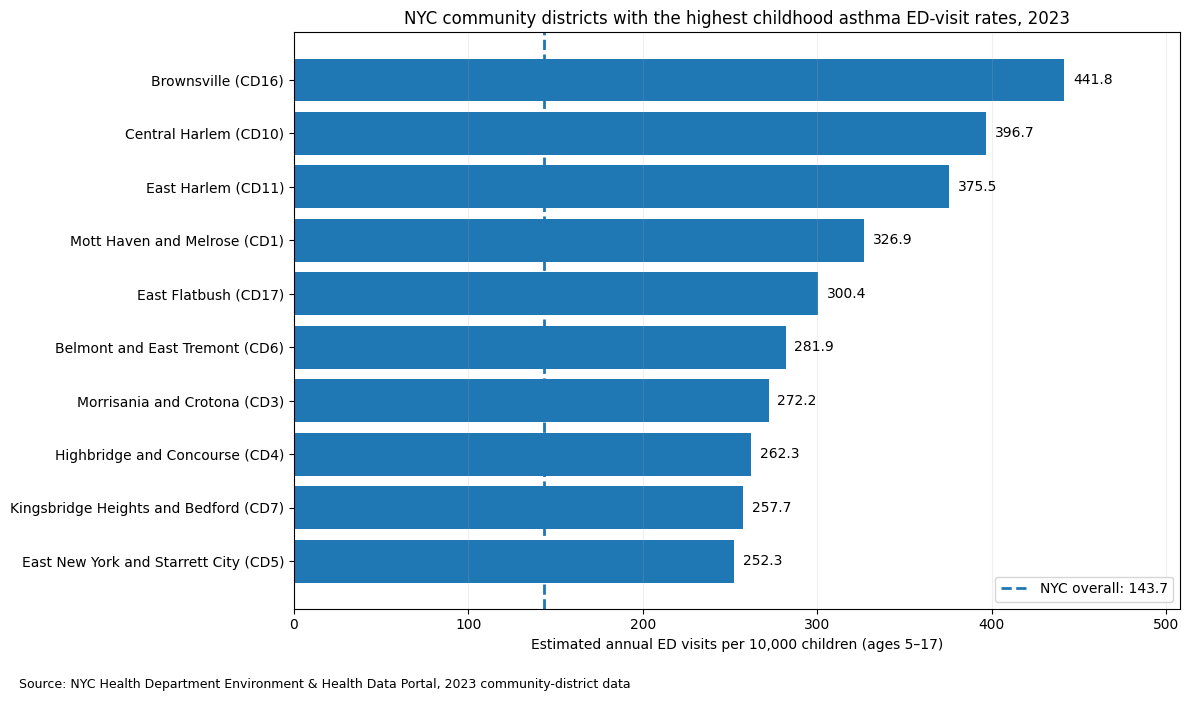

In [ ]:
import matplotlib.pyplot as plt

top10_plot = (
    asthma.nlargest(10, "rate")
    .sort_values("rate")
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top10_plot["district"],
    top10_plot["rate"]
)

ax.axvline(
    CITYWIDE_RATE,
    linestyle="--",
    linewidth=2,
    label=f"NYC overall: {CITYWIDE_RATE:.1f}"
)

for i, value in enumerate(top10_plot["rate"]):
    ax.text(
        value + 5,
        i,
        f"{value:.1f}",
        va="center"
    )

ax.set_xlim(0, top10_plot["rate"].max() * 1.15)

ax.set_xlabel(
    "Estimated annual ED visits per 10,000 children (ages 5–17)"
)

ax.set_title(
    "NYC community districts with the highest childhood "
    "asthma ED-visit rates, 2023"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)

fig.text(
    0.02, 0.01,
    "Source: NYC Health Department Environment & Health Data Portal, "
    "2023 community-district data",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    folder / "q3_asthma_top10.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

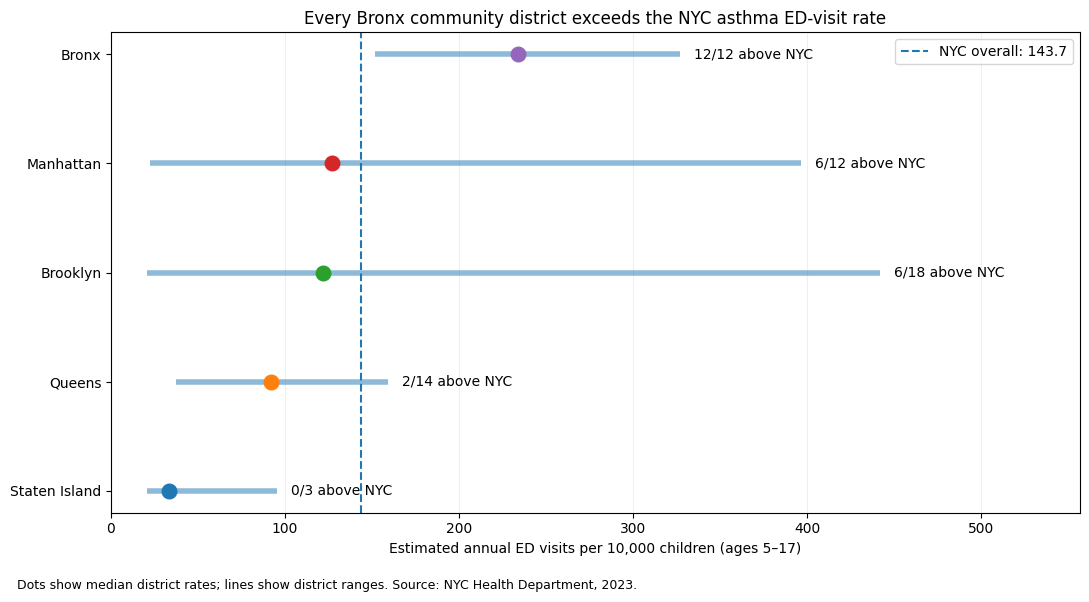

In [ ]:
plot_data = borough_summary.sort_values(
    "median_district_rate"
)

fig, ax = plt.subplots(figsize=(11, 6))

for i, (_, row) in enumerate(plot_data.iterrows()):

    # Range from lowest to highest district.
    ax.hlines(
        y=i,
        xmin=row["lowest_district_rate"],
        xmax=row["highest_district_rate"],
        linewidth=4,
        alpha=0.5
    )

    # Median district rate.
    ax.scatter(
        row["median_district_rate"],
        i,
        s=110,
        zorder=3
    )

    # Number of districts above the NYC benchmark.
    ax.text(
        row["highest_district_rate"] + 8,
        i,
        f'{int(row["districts_above_citywide"])}/'
        f'{int(row["districts"])} above NYC',
        va="center",
        fontsize=10
    )

ax.axvline(
    CITYWIDE_RATE,
    linestyle="--",
    label=f"NYC overall: {CITYWIDE_RATE:.1f}"
)

ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data["borough"])

ax.set_xlim(
    0,
    plot_data["highest_district_rate"].max() + 115
)

ax.set_xlabel(
    "Estimated annual ED visits per 10,000 children (ages 5–17)"
)

ax.set_title(
    "Every Bronx community district exceeds the NYC asthma ED-visit rate"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)

fig.text(
    0.02, 0.01,
    "Dots show median district rates; lines show district ranges. "
    "Source: NYC Health Department, 2023.",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    folder / "q3_borough_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

Median district visit count: 219.0
Districts above both references: 22


,district,borough,rate,visits
16,Brownsville (CD16),Brooklyn,441.8,627
30,Central Harlem (CD10),Manhattan,396.7,619
32,East Harlem (CD11),Manhattan,375.5,628
7,Mott Haven and Melrose (CD1),Bronx,326.9,585
20,East Flatbush (CD17),Brooklyn,300.4,563
0,Belmont and East Tremont (CD6),Bronx,281.9,459
6,Morrisania and Crotona (CD3),Bronx,272.2,473
2,Highbridge and Concourse (CD4),Bronx,262.3,697
4,Kingsbridge Heights and Bedford (CD7),Bronx,257.7,619
21,East New York and Starrett City (CD5),Brooklyn,252.3,763


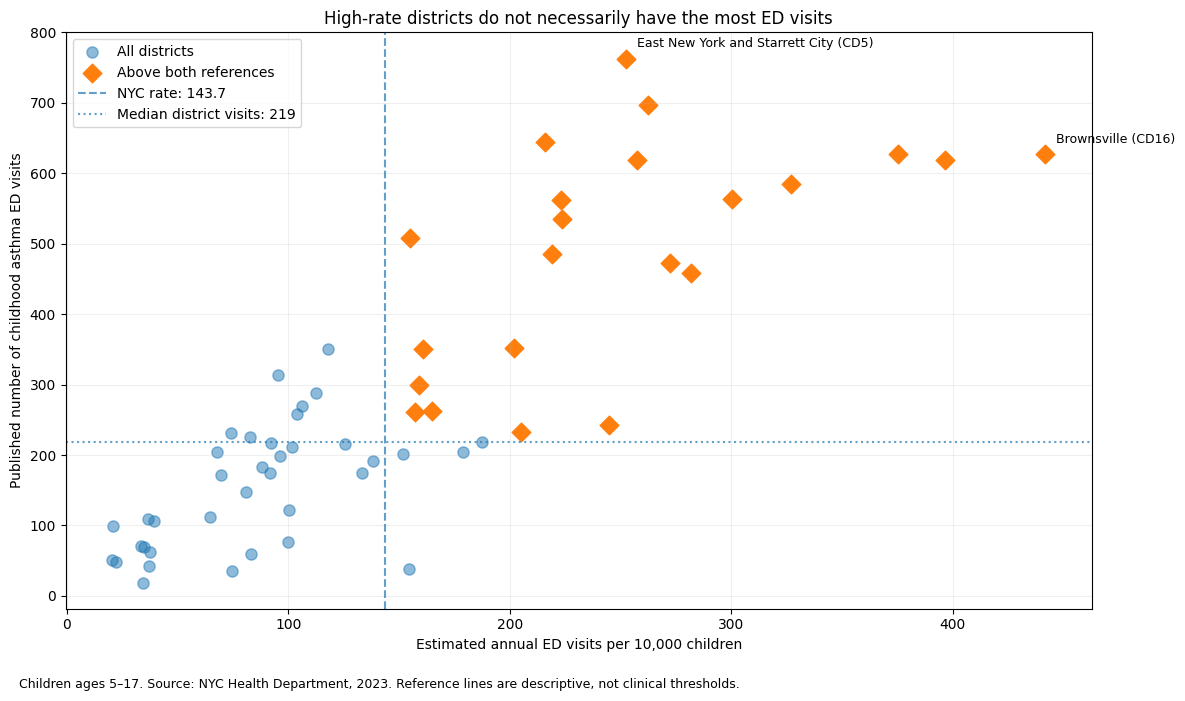

In [ ]:
# Use the median district visit count as an exploratory reference.
median_visits = asthma["visits"].median()

# Identify districts above both the citywide rate
# and the median district visit count.
asthma["high_rate_and_volume"] = (
    (asthma["rate"] > CITYWIDE_RATE) &
    (asthma["visits"] > median_visits)
)

candidates = asthma[
    asthma["high_rate_and_volume"]
].copy()

print("Median district visit count:", median_visits)
print("Districts above both references:", len(candidates))

display(
    candidates.sort_values(
        ["rate", "visits"],
        ascending=False
    )[["district", "borough", "rate", "visits"]]
)

fig, ax = plt.subplots(figsize=(12, 7))

# Show all districts.
ax.scatter(
    asthma["rate"],
    asthma["visits"],
    s=65,
    alpha=0.5,
    label="All districts"
)

# Emphasize districts above both reference values.
ax.scatter(
    candidates["rate"],
    candidates["visits"],
    s=90,
    marker="D",
    label="Above both references"
)

ax.axvline(
    CITYWIDE_RATE,
    linestyle="--",
    alpha=0.7,
    label=f"NYC rate: {CITYWIDE_RATE:.1f}"
)

ax.axhline(
    median_visits,
    linestyle=":",
    alpha=0.7,
    label=f"Median district visits: {median_visits:.0f}"
)

# Label the highest-rate district and the district
# with the largest number of visits.
notable = pd.concat([
    asthma.nlargest(1, "rate"),
    asthma.nlargest(1, "visits")
]).drop_duplicates("district_id")

for _, row in notable.iterrows():
    ax.annotate(
        row["district"],
        (row["rate"], row["visits"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel(
    "Estimated annual ED visits per 10,000 children"
)

ax.set_ylabel(
    "Published number of childhood asthma ED visits"
)

ax.set_title(
    "High-rate districts do not necessarily have the most ED visits"
)

ax.legend()
ax.grid(alpha=0.2)

fig.text(
    0.02, 0.01,
    "Children ages 5–17. Source: NYC Health Department, 2023. "
    "Reference lines are descriptive, not clinical thresholds.",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    folder / "q3_rate_vs_visits.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import shutil
from google.colab import files

asthma.to_csv(
    folder / "asthma_2023_analysis.csv",
    index=False
)

borough_summary.to_csv(
    folder / "borough_summary.csv",
    index=False
)

candidates.to_csv(
    folder / "priority_assessment_candidates.csv",
    index=False
)

shutil.make_archive(
    "Q3_asthma_data_and_charts",
    "zip",
    root_dir=".",
    base_dir="q3_asthma"
)

files.download("Q3_asthma_data_and_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>